[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QGAN_IntrusionDetection_Rahman2023.ipynb)

# Quantum GAN (qGAN) on NSL-KDD for intrusion detection: Rahman et al. 2023 step by step

**Paper.** Md Abdur Rahman, Hossain Shahriar, Victor Clincy, Md Faruque Hossain and Muhammad Rahman, *A Quantum Generative Adversarial Network-based Intrusion Detection System*, 2023 IEEE 47th Annual Computers, Software, and Applications Conference (COMPSAC), pp. 1810-1815. DOI: [10.1109/COMPSAC57700.2023.00280](https://doi.org/10.1109/COMPSAC57700.2023.00280). (The notebook is written from the paper text only; the authors' code is not public.)

**What this notebook does.** The paper applies the Qiskit *qGAN* of Zoufal, Lucchi and Woerner (*Quantum generative adversarial networks for learning and loading random distributions*, 2019) to the **NSL-KDD** intrusion data. A qGAN has a **quantum generator** (a few qubits, Hadamard gates, trainable `RY` rotations and a linear chain of `CZ` gates) that loads a probability distribution over `2^n` grid points into the amplitudes of an `n`-qubit state, and a **classical neural-network discriminator** that tries to tell samples of the real data from samples of the generator. Both are trained against each other with the binary cross-entropy of the paper's equation (5), and the training is monitored with the generator and discriminator losses, the **relative entropy** between the generated and the target distribution, and the **cumulative distribution functions** (CDF) of the generated and the real data (the paper's Figures 4 and 5).

1. Downloads NSL-KDD, preprocesses it (robust scaling, one-hot, min-max, PCA) and turns the principal components of **benign** traffic into a discrete target distribution on a `2^3 = 8` point grid (one feature, 3 qubits) and on an `8 x 8` grid (two features, 6 qubits).
2. Builds the generator as a Qiskit circuit (drawn in the circuit section), simulates it exactly in PyTorch so that it is differentiable, and **asserts** that the simulator reproduces Qiskit's state vector and the gradient of Qiskit's `SamplerQNN` + `TorchConnector` (the route the paper took).
3. Trains the qGAN for 100 epochs from 4 random initialisations, re-draws Figures 4 and 5 of the paper (losses, relative entropy for 50 and 100 epochs, CDF and CDF difference), and checks each qualitative claim of the paper with a stated criterion.
4. Adds what the paper does not have: two **classical GAN baselines** trained on identical inputs with the same discriminator design and training loop, a 6-qubit two-feature generator, and a small **intrusion-detection experiment** that uses the trained generator as a density model of benign traffic (anomaly score = `-log p_G`), compared with Isolation Forest, one-class SVM and Random Forest on the same inputs and on all features.

**How to run it.** Open in Google Colab (CPU runtime is enough), *Runtime -> Run all*. `FAST_MODE = True` is a class demo (about 10 minutes). `FAST_MODE = False` uses the paper's 100 epochs and four initialisations; the stored outputs come from the run stated in the configuration cell. No quantum computer and no token are needed (NSL-KDD is public).

**What you get at the end.** Real-data exploration plots, drawn generator circuits, the paper's loss / relative-entropy / CDF figures re-drawn from our own run, the quantum-versus-classical comparison, an honest detection table, and a claim-by-claim verdict.

## The paper in one page

**Problem.** Intrusion detection with a generative model. Classical ML security systems are said to be fragile and slow on big data; the authors propose a quantum generative adversarial network that learns the distribution of NSL-KDD records.

**Data.** NSL-KDD (the cleaned KDD'99), described through its four attribute groups (basic, content, traffic, host). Which features enter the qGAN, how many qubits are used and how the records are mapped to the grid is **not stated**.

**Method (Sections III-IV).**
* Generator: `n` qubits in `|0>`, Hadamard gates (uniform superposition), parameterised `RY` rotations, `CZ` gates in a *linear* entanglement topology; "hardware-efficient ansatz with `r` repetitions". The generator is a `SamplerQNN` wrapped in a `TorchConnector`; the Sampler is state-vector based (exact probabilities), optional shot noise; initial weights fixed for reproducibility.
* Discriminator: a classical neural network (PyTorch). Loss: binary cross-entropy, eq. (5). Optimiser: Adam. Hardware: none (Google Colab simulator).
* Monitoring: generator and discriminator loss, relative entropy to the target distribution, CDF of generated versus real data.

**Results (Section V, Figures 4 and 5; there is no table of numbers).**
1. Loss curves of generator and discriminator over training (Fig. 4 left).
2. The relative entropy converges for various initialisations, for 50 and for 100 epochs (Fig. 4 right).
3. The CDF of the generated data approaches the CDF of the real data; their difference is plotted for 50 epochs (Fig. 5).
4. Runs on a classical simulator in Colab, with `O(poly(n))` gates for the generator.
5. Conclusion: the qGAN "can detect attack packets ... based on certain patterns or by profiling to detect anomalies" and quantum machine learning "can outperform" classical machine learning. **No detection metric and no classical comparison is reported.**

### What follows the paper and what had to be chosen

The paper is a six-page conference paper. It gives the circuit family, the optimiser and three qualitative figures, but no numbers, no feature choice, no qubit count, no epochs-per-figure detail, no learning rates and no detection experiment. Every such choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NSL-KDD | `KDDTrain+` and `KDDTest+` from the public GitHub mirror `defcom17/NSL_KDD` (fallback mirror `jmnwong/NSL-KDD-Dataset`); stratified 80 / 20 split of `KDDTrain+` |
| Which feature(s) go into the qGAN | not stated | **CHOICE**: the first principal component PC1 of the preprocessed 122-column feature matrix (robust scaling -> one-hot -> min-max -> PCA, fitted on the training split without labels; it carries 41 % of the variance); main experiment 1-D. Extension: PC1 and PC2 (6 qubits) |
| Training distribution | "the NSL-KDD dataset" | **CHOICE**: benign records of the training split only (the GAN models normal traffic; attacks are what it should not generate) |
| Grid / qubits | `2^n` values for `n` qubits | **CHOICE**: 3 qubits per feature = 8 equal-width bins between the 0.5 % and 99.5 % quantiles of benign PC1 (values outside go into the end bins) |
| Generator | `H` on all qubits, trainable `RY`, linear `CZ`, `r` repetitions, uniform input state | exactly that, `n_local(n, "ry", "cz", entanglement="linear", reps=3)` after `H`; 3 repetitions (**CHOICE**, `r` not stated), 12 parameters for 3 qubits |
| Initial weights | "fixed to ensure reproducibility" | uniform in `[0, 2 pi)` from `numpy.random.default_rng(seed)` (**CHOICE**) |
| Sampler | state vector, optional shot noise | exact probabilities (training); the Qiskit `SamplerQNN` route with a shot-based sampler is used as a cross-check of values and gradients |
| Discriminator | "a neural network" | `Linear(K, 50) - LeakyReLU(0.2) - Linear(50, 20) - LeakyReLU(0.2) - Linear(20, 1) - Sigmoid` (**CHOICE**, the layout of the Qiskit qGAN tutorial). Its input is the **one-hot encoding of the grid cell** (`K = 8` or `64` inputs), so that it can represent any function on the cells; with the raw cell index as a single input (what the Qiskit tutorial feeds) the discriminator stayed near 0.5 in pilots and the generator got no usable signal. The classical MLP GAN produces continuous samples and therefore needs a discriminator on the continuous coordinate (`d` inputs, in cell-index units) |
| Loss | eq. (5): BCE weighted by the generator probabilities `p_j(theta)` | discriminator: `BCE(D(real), 1) + sum_j p_j BCE(D(x_j), 0)`; generator: `sum_j p_j BCE(D(x_j), 1)` (the usual non-saturating form) |
| Optimiser | Adam | Adam, `betas = (0.7, 0.999)`, `lr_G = 0.002`, `lr_D = 0.003`, **3 discriminator updates per generator update**, batch 10, 1000 benign training samples (**CHOICE**; chosen on 60-epoch pilot runs on the 1-D problem (initialisations 42-45, with the target distribution as the diagnostic, no test data). The generator has to be slow compared with the discriminator: with equal rates and one update each, the discriminator output stayed at 0.5 and the generator received almost no signal) |
| Epochs, initialisations | 50 and 100 epochs, "various initialisations" | 100 epochs, 4 initialisations (seeds 42-45); the 50-epoch value is read from the same run |
| Relative entropy | "distance between trained and target distribution" | `KL(target || generated)` (always finite); the direction used by the Qiskit tutorial, `KL(generated || target)`, is also given for the 1-D case |
| CDF figure | CDF generated vs real, and their difference | the same, with the target CDF taken from the full benign pool |
| Detection | stated as the goal; no experiment | **extra**: anomaly score `-log p_G(cell of the flow)` on the 20 % hold-out and `KDDTest+`, compared with classical detectors on identical inputs |
| Classical comparison | none (only the claim that quantum may outperform) | **extra**: a softmax-probability GAN (same loss, same discriminator, `2^n` parameters) and a classical MLP GAN that outputs samples |

## 1. Setup

The first cell installs pinned, tested versions (nothing happens locally if they are importable). On Colab a *session restart* may be requested after the install; if so, run all cells again. PyTorch, scikit-learn, pandas and matplotlib come with Colab.

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    return importlib.util.find_spec(m) is not None
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_machine_learning", "torch", "pylatexenc"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc"], check=False)
    print("installed pinned versions; if Colab asks for a restart, restart and run all cells again")
else:
    print("pinned libraries already importable; nothing to install")

pinned libraries already importable; nothing to install


### 1.1 Configuration

Every tunable constant is here. `FAST_MODE = True` is the class demo (30 epochs, 2 initialisations, 500 training samples). `FAST_MODE = False` follows the paper's 100 epochs with four random initialisations and 1000 training samples (the Qiskit tutorial's size); the two-feature extension uses 2 initialisations and 60 epochs to bound the run time (about 20 minutes in total on a shared laptop CPU).

In [2]:
FAST_MODE = False           # True: demo (about 10 min). False: 100 epochs, 5 initialisations (see the runtime note in the intro)
SEED = 42                   # global seed: data split, torch, numpy
DATA_DIR = "data"           # NSL-KDD files are cached here
IBM_TOKEN = ""              # not used: the paper (and this notebook) run on a simulator only

M_QUBITS = 3                # CHOICE: qubits per feature -> 2**3 = 8 grid values per feature
GEN_REPS = 3                # CHOICE: repetitions r of the 1-D generator ansatz (12 parameters on 3 qubits)
GEN_REPS_2D = 4             # CHOICE: repetitions for the 6-qubit, two-feature generator (30 parameters)
BATCH = 10                  # CHOICE (Qiskit qGAN tutorial value)
LR_G, LR_D = 0.002, 0.003   # CHOICE: not stated in the paper (60-epoch pilots; see the table above)
N_D_STEPS = 3               # CHOICE: discriminator updates (fresh real mini-batches) per generator update
ADAM_BETAS = (0.7, 0.999)   # CHOICE: Qiskit tutorial value
N_VAL = 2000                # benign flows kept apart for thresholds
BENIGN_FPR = 0.05           # detection extra: threshold at the 95th percentile of benign validation scores
SHOTS_CHECK = 200_000     # shots of the Qiskit sampler in the equivalence check
KL_FLOOR = 1e-12            # floor of the generated probability inside the relative entropy
PAPER_EPOCHS = (50, 100)    # the paper shows the relative entropy for 50 and for 100 epochs
C_KL_REL = 0.25             # claim criterion (our choice, fixed before the final run): median KL at the last epoch < 0.25 x median KL after epoch 1
C_KS = 0.10                 # claim criterion: median maximal CDF gap at the last epoch < 0.10

if FAST_MODE:
    EPOCHS, N_TRAIN = 30, 500
    SEEDS_1D, SEEDS_ATT, SEEDS_2D = [42, 43], [42], [42]
    EPOCHS_2D = 30
else:
    EPOCHS, N_TRAIN = 100, 1000
    SEEDS_1D, SEEDS_ATT, SEEDS_2D = [42, 43, 44, 45], [42, 43], [42, 43]
    EPOCHS_2D = 60
E_HALF = EPOCHS // 2        # "50 epochs" of the paper (15 in FAST_MODE)
print("FAST_MODE =", FAST_MODE, "| epochs", EPOCHS, "| training samples", N_TRAIN, "| seeds 1-D / attack-class / 2-D:", SEEDS_1D, SEEDS_ATT, SEEDS_2D)

FAST_MODE = False | epochs 100 | training samples 1000 | seeds 1-D / attack-class / 2-D: [42, 43, 44, 45] [42, 43] [42, 43]


In [3]:
import os, time, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests, torch, torch.nn as nn
from scipy.stats import entropy
warnings.filterwarnings("ignore")
import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit.library import n_local
from qiskit.quantum_info import Statevector
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from IPython.display import display

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)                      # tiny tensors: one thread is fastest and kind to a shared CPU
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
FAM_COLORS = {"Normal": "tab:blue", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:green", "U2R": "tab:purple", "Other": "grey"}
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6


## 2. Data: NSL-KDD

NSL-KDD is the cleaned version of KDD Cup 99: 41 features per connection (3 categorical: `protocol_type`, `service`, `flag`; the rest numeric) and a label with 22 attack names in `KDDTrain+` (more in `KDDTest+`) that group into four families: **DoS**, **Probe**, **R2L**, **U2R**. The files are downloaded from a public GitHub mirror (a second mirror is the fallback). No token is needed; a gated dataset would need the reader's own Hugging Face token in Colab Secrets, resolved as below.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
# NSL-KDD is public on GitHub: the token is not needed or used here.

NSL_COLS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
            "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
            "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count",
            "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
            "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
            "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack", "difficulty"]
FAMILY = {"normal": "Normal"}
for fam_, names in {"DoS": "back land neptune pod smurf teardrop apache2 udpstorm processtable worm mailbomb",
                    "Probe": "ipsweep nmap portsweep satan mscan saint",
                    "R2L": "ftp_write guess_passwd imap multihop phf spy warezclient warezmaster sendmail named snmpgetattack snmpguess xlock xsnoop httptunnel",
                    "U2R": "buffer_overflow loadmodule perl rootkit ps sqlattack xterm"}.items():
    FAMILY.update({n: fam_ for n in names.split()})
URLS = {"KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                          "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
        "KDDTest+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                         "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"]}

def download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            open(path, "wb").write(r.content); return path
        except Exception as e:
            print("download failed:", u, repr(e)[:100])
    raise RuntimeError("no mirror worked for " + path)

def load_nsl(name):
    path = download(URLS[name], os.path.join(DATA_DIR, name))
    raw = pd.read_csv(path, header=None, names=NSL_COLS)
    raw["family"] = raw["attack"].map(FAMILY).fillna("Other")
    raw["y"] = (raw["attack"] != "normal").astype(int)         # 0 = normal, 1 = attack (positive class)
    return raw

RAW_TR, RAW_TE = load_nsl("KDDTrain+.txt"), load_nsl("KDDTest+.txt")
print("KDDTrain+:", RAW_TR.shape, "| attack share", round(RAW_TR.y.mean(), 3), "| KDDTest+:", RAW_TE.shape, "| attack share", round(RAW_TE.y.mean(), 3))
print("unmapped attack names:", sorted(set(RAW_TR.attack[RAW_TR.family == "Other"]) | set(RAW_TE.attack[RAW_TE.family == "Other"])))

KDDTrain+: (125973, 45) | attack share 0.465 | KDDTest+: (22544, 45) | attack share 0.569
unmapped attack names: []


### 2.1 Splits

Labels are used **only** for the stratified split, to select the benign flows the GAN models, for colouring, and to score the detection extra. The 80 / 20 stratified split of `KDDTrain+` (by attack family) gives a **training split** and a **hold-out test set**. Inside the training split, 2000 benign flows are kept apart as a **benign validation set** (thresholds); the remaining benign flows are the **benign pool**: they define the target distribution and the GAN's training samples. `KDDTest+` (which contains attacks absent from training) is a second, harder test set.

In [5]:
FEATURES = [c for c in NSL_COLS if c not in ("attack", "difficulty")]
CAT = ["protocol_type", "service", "flag"]
fam_all, y_all = RAW_TR["family"].values, RAW_TR["y"].values
idx = np.arange(len(RAW_TR))
TR_ALL, HO = train_test_split(idx, test_size=0.2, stratify=fam_all, random_state=SEED)       # training split / hold-out
ben_tr = np.random.default_rng(SEED).permutation(TR_ALL[y_all[TR_ALL] == 0])
BEN_VAL, BEN_POOL = ben_tr[:N_VAL], ben_tr[N_VAL:]                                            # benign validation / benign pool
ATT_POOL = np.random.default_rng(SEED).permutation(TR_ALL[y_all[TR_ALL] == 1])                # attack flows of the training split (supervised extra only)
assert not (set(BEN_POOL) & set(HO)) and not (set(BEN_POOL) & set(BEN_VAL)) and not (set(BEN_VAL) & set(HO)), "leakage between splits"
print(f"training split {len(TR_ALL):,} | hold-out {len(HO):,} (attack share {y_all[HO].mean():.3f}) | KDDTest+ {len(RAW_TE):,} (attack share {RAW_TE.y.mean():.3f})")
print(f"benign pool {len(BEN_POOL):,} | benign validation {len(BEN_VAL):,} | attack flows in the training split {len(ATT_POOL):,}")

training split 100,778 | hold-out 25,195 (attack share 0.465) | KDDTest+ 22,544 (attack share 0.569)
benign pool 51,874 | benign validation 2,000 | attack flows in the training split 46,904


### 2.2 Preprocessing (fitted on the training split only, no labels)

Robust scaling of the numeric columns, one-hot encoding of the three categorical columns, min-max scaling, then a **PCA fitted on the training split** (no labels). The first two components are kept: **PC1** is the one-dimensional data of the main experiment, **PC1 and PC2** those of the 6-qubit extension. The hold-out and `KDDTest+` are only transformed.

Then every component is cut into `2^3 = 8` equal-width bins between the 0.5 % and 99.5 % quantiles of **benign-pool** values (values outside fall into the first or last bin; the cut points use benign flows only and no test data). A flow is thereby a *grid cell*, and the **target distribution** is the share of benign-pool flows per cell. This is the discrete distribution that the qGAN must load into its amplitudes: a generator on `n` qubits has `2^n` outcomes, one per cell.

In [6]:
class Prep:
    # robust scaling (numeric) -> one-hot (categorical) -> MinMax [0,1] -> PCA. Fitted on feature rows only (no labels).
    def fit(self, df, n_comp=2):
        self.num_cols = [c for c in df.columns if c not in CAT]
        self.rs = RobustScaler().fit(df[self.num_cols].astype(float))
        self.ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(df[CAT])
        self.mm = MinMaxScaler().fit(self._raw(df))
        self.pca = PCA(n_components=n_comp, random_state=SEED).fit(self.mm.transform(self._raw(df)))
        return self
    def _raw(self, df):
        return np.hstack([self.rs.transform(df[self.num_cols].astype(float)), self.ohe.transform(df[CAT])])
    def full(self, df):                      # all 122 preprocessed columns (for the all-feature baselines)
        return self.mm.transform(self._raw(df))
    def pcs(self, df):                       # raw PCA coordinates
        return self.pca.transform(self.full(df))

prep = Prep().fit(RAW_TR.loc[TR_ALL, FEATURES], n_comp=2)
PC_TR, PC_TE = prep.pcs(RAW_TR[FEATURES]), prep.pcs(RAW_TE[FEATURES])           # transform only
FULL_TR, FULL_TE = prep.full(RAW_TR[FEATURES]), prep.full(RAW_TE[FEATURES])
print("numeric columns:", len(prep.num_cols), "| one-hot columns:", FULL_TR.shape[1] - len(prep.num_cols), "| preprocessed columns:", FULL_TR.shape[1])
print("PCA explained variance ratio (PC1, PC2):", np.round(prep.pca.explained_variance_ratio_, 3), "| sum", round(float(prep.pca.explained_variance_ratio_.sum()), 3))

NB = 2 ** M_QUBITS
LO, HI = np.percentile(PC_TR[BEN_POOL], [0.5, 99.5], axis=0)                     # CHOICE: benign-pool quantiles define the grid
def feat_bins(pc, d):                      # (n, d) integer bin of each of the first d components
    b = np.floor((pc[:, :d] - LO[:d]) / (HI[:d] - LO[:d]) * NB).astype(int)
    return np.clip(b, 0, NB - 1)
def joint_cell(b):                         # basis-state index k = sum_j b_j * 2**(M*j); qubit i is bit i of k (Qiskit little-endian)
    return sum(b[:, j].astype(int) << (M_QUBITS * j) for j in range(b.shape[1]))
def grid_coords(d):                        # (2**(M*d), d) cell indices 0..NB-1 of every feature (the discriminator input, like the grid values of the Qiskit qGAN)
    k = np.arange(NB ** d)
    return np.stack([((k >> (M_QUBITS * j)) & (NB - 1)).astype(float) for j in range(d)], axis=1)
def pmf_of(cell_ids, d):
    return np.bincount(cell_ids, minlength=NB ** d) / len(cell_ids)

CELL_TR = {d: joint_cell(feat_bins(PC_TR, d)) for d in (1, 2)}
CELL_TE = {d: joint_cell(feat_bins(PC_TE, d)) for d in (1, 2)}
TARGET = {d: pmf_of(CELL_TR[d][BEN_POOL], d) for d in (1, 2)}
ATT_TARGET = {d: pmf_of(CELL_TR[d][ATT_POOL], d) for d in (1, 2)}
GRID = {d: torch.eye(NB ** d) for d in (1, 2)}      # one-hot encoding of every grid cell = discriminator input of the exact-pmf GANs
print("grid edges (PC1):", np.round(np.linspace(LO[0], HI[0], NB + 1), 2))
print("target pmf, benign pool, 1-D (8 cells):", np.round(TARGET[1], 3))
print("attack-class pmf, 1-D                 :", np.round(ATT_TARGET[1], 3))
print("2-D target: 64 cells, empty cells:", int((TARGET[2] == 0).sum()))

numeric columns: 38 | one-hot columns: 84 | preprocessed columns: 122
PCA explained variance ratio (PC1, PC2): [0.412 0.157] | sum 0.569
grid edges (PC1): [-0.22 -0.02  0.19  0.39  0.6   0.8   1.01  1.21  1.42]
target pmf, benign pool, 1-D (8 cells): [0.009 0.027 0.054 0.065 0.121 0.187 0.177 0.36 ]
attack-class pmf, 1-D                 : [0.809 0.013 0.024 0.02  0.022 0.078 0.034 0.002]
2-D target: 64 cells, empty cells: 7


## Dataset Exploration and Visualisation

NSL-KDD is a table of real connection records that the notebook downloads; nothing in this section is simulated. It prints the shape, the feature names and the original labels with their counts, plots the real class distribution (original attack names, attack family, binary label), and draws two-dimensional scatter plots of **real flows coloured by their ground-truth family**: first the raw PCA coordinates (PC1 against PC2, fitted on the training split, with the grid of the qGAN), then the same flows in the `[0, 1]` unit square that is the discriminator's data space. (The generator has **no data-angle encoding**: its input is the uniform state made by Hadamard gates, and the data enter only through the target distribution and the discriminator. Hence there is no `[0, pi]` angle scaling here; the `[0, 1]` coordinates are what the discriminator sees.) Labels are used only for colouring.

KDDTrain+ shape: (125973, 45) | KDDTest+ shape: (22544, 45)

41 original features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

original label column 'attack' in KDDTrain+ ( 23 distinct values):
attack
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep    

attack names in KDDTest+ that never occur in KDDTrain+: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


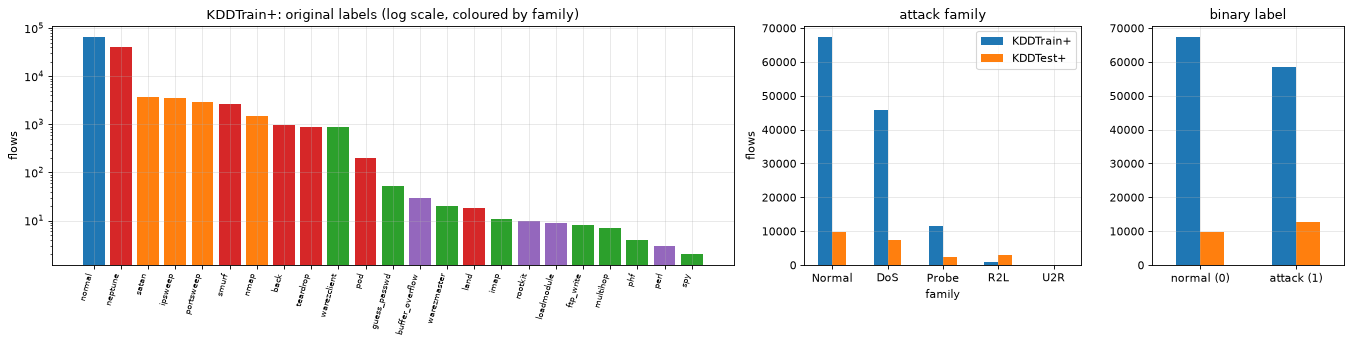

In [7]:
print("KDDTrain+ shape:", RAW_TR.shape, "| KDDTest+ shape:", RAW_TE.shape)
print("\n41 original features:", FEATURES)
print("\noriginal label column 'attack' in KDDTrain+ (", RAW_TR.attack.nunique(), "distinct values):")
print(RAW_TR.attack.value_counts().to_string())
print("\nattack family counts, KDDTrain+:", {k: int(v) for k, v in RAW_TR.family.value_counts().items()})
print("attack family counts, KDDTest+ :", {k: int(v) for k, v in RAW_TE.family.value_counts().items()})
print("binary label (0 = normal, 1 = attack), KDDTrain+:", {k: int(v) for k, v in RAW_TR.y.value_counts().items()}, "| GAN benign pool:", len(BEN_POOL), "flows, all label 0")
print("attack names in KDDTest+ that never occur in KDDTrain+:", sorted(set(RAW_TE.attack) - set(RAW_TR.attack)))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [3.2, 1.3, 0.9]})
vc = RAW_TR.attack.value_counts()
ax[0].bar(range(len(vc)), vc.values, color=[FAM_COLORS[FAMILY.get(k, "Other")] for k in vc.index])
ax[0].set_xticks(range(len(vc))); ax[0].set_xticklabels(vc.index, rotation=75, ha="right", fontsize=7)
ax[0].set_yscale("log"); ax[0].set_title("KDDTrain+: original labels (log scale, coloured by family)"); ax[0].set_ylabel("flows")
fc = pd.concat([RAW_TR.family.value_counts().rename("KDDTrain+"), RAW_TE.family.value_counts().rename("KDDTest+")], axis=1).fillna(0).reindex(["Normal", "DoS", "Probe", "R2L", "U2R"])
fc.plot.bar(ax=ax[1], rot=0, color=["tab:blue", "tab:orange"]); ax[1].set_title("attack family"); ax[1].set_ylabel("flows")
bc = pd.DataFrame({"KDDTrain+": RAW_TR.y.value_counts().sort_index(), "KDDTest+": RAW_TE.y.value_counts().sort_index()})
bc.index = ["normal (0)", "attack (1)"]; bc.plot.bar(ax=ax[2], rot=0, color=["tab:blue", "tab:orange"], legend=False); ax[2].set_title("binary label")
plt.tight_layout(); plt.show()

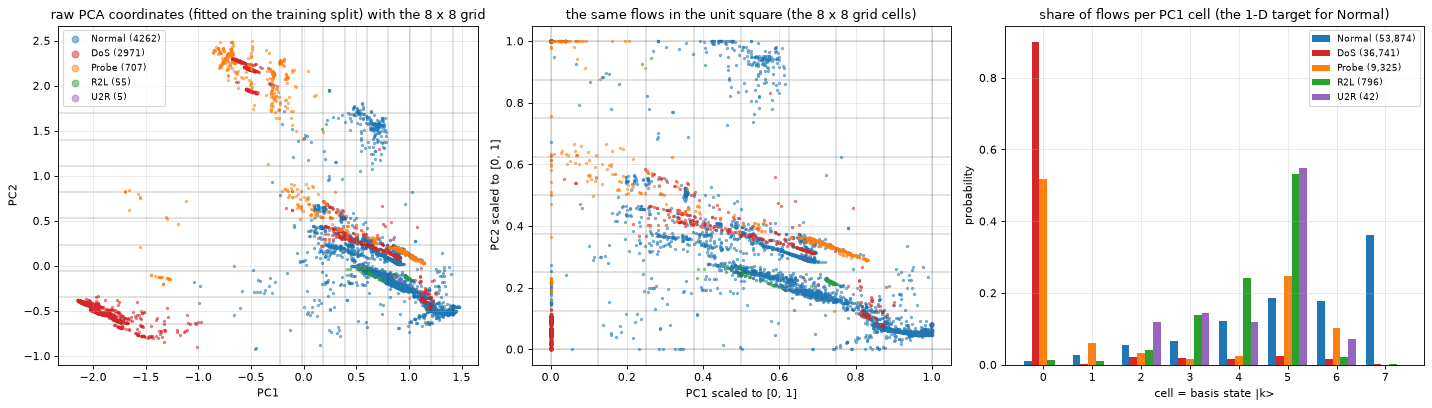

explained variance of PC1, PC2: [0.412 0.157]


In [8]:
# 2-D scatter of real flows coloured by ground-truth family (training split, 8000 random flows)
sub = np.random.default_rng(SEED).choice(TR_ALL, 8000, replace=False)
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
for fam in ["Normal", "DoS", "Probe", "R2L", "U2R"]:
    m = RAW_TR.family.values[sub] == fam
    if m.sum():
        ax[0].scatter(PC_TR[sub[m], 0], PC_TR[sub[m], 1], s=4, c=FAM_COLORS[fam], alpha=0.5, label=f"{fam} ({m.sum()})")
        U = np.clip((PC_TR[sub[m]] - LO[:2]) / (HI[:2] - LO[:2]), 0, 1)
        ax[1].scatter(U[:, 0], U[:, 1], s=4, c=FAM_COLORS[fam], alpha=0.5, label=fam)
for e in np.linspace(LO[0], HI[0], NB + 1): ax[0].axvline(e, c="k", lw=0.4, alpha=0.5)
for e in np.linspace(LO[1], HI[1], NB + 1): ax[0].axhline(e, c="k", lw=0.4, alpha=0.5)
ax[0].set_title("raw PCA coordinates (fitted on the training split) with the 8 x 8 grid"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(markerscale=3, fontsize=8)
for e in np.linspace(0, 1, NB + 1): ax[1].axvline(e, c="k", lw=0.4, alpha=0.5); ax[1].axhline(e, c="k", lw=0.4, alpha=0.5)
ax[1].set_title("the same flows in the unit square (the 8 x 8 grid cells)"); ax[1].set_xlabel("PC1 scaled to [0, 1]"); ax[1].set_ylabel("PC2 scaled to [0, 1]")
# target distribution of PC1 cells: benign pool versus each attack family
w = 0.16
for i, fam in enumerate(["Normal", "DoS", "Probe", "R2L", "U2R"]):
    sel = TR_ALL[RAW_TR.family.values[TR_ALL] == fam]
    ax[2].bar(np.arange(NB) + (i - 2) * w, pmf_of(CELL_TR[1][sel], 1), width=w, color=FAM_COLORS[fam], label=f"{fam} ({len(sel):,})")
ax[2].set_title("share of flows per PC1 cell (the 1-D target for Normal)"); ax[2].set_xlabel("cell = basis state |k>"); ax[2].set_ylabel("probability"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("explained variance of PC1, PC2:", np.round(prep.pca.explained_variance_ratio_, 3))

## 3. The quantum generator and how it is simulated

**Circuit** (paper, Section III-D and Fig. 3). `n` qubits start in `|0>`; a Hadamard gate on each qubit makes the uniform superposition (the paper: "takes a uniform distribution as an input state"); then the trainable part, a hardware-efficient ansatz with `r` repetitions: a layer of `RY(theta)` rotations on every qubit, and `r` times [a chain of `CZ` gates between neighbouring qubits (`linear` entanglement), another layer of `RY` rotations]. Measuring all qubits gives a bit string `k`; the generator's distribution is `p_j(theta) = |<j| U(theta) |+>^n|^2` over the `2^n` grid cells. With `n` qubits and `r` repetitions it has `(r + 1) n` parameters and `n + (r + 1) n + r (n - 1)` gates: **polynomial in `n`**, while the distribution it can load has `2^n` entries.

**Simulation.** All gates are real (`H`, `RY`, `CZ`), so the state vector is real. Training needs thousands of gradient evaluations, so the generator is simulated exactly in PyTorch (a Kronecker product of `RY` matrices per layer, a sign vector for the `CZ` chain), which makes `p_j(theta)` differentiable. The next section **draws the Qiskit circuit** and **asserts** that this simulator equals Qiskit's `Statevector` and the gradient obtained through Qiskit's `SamplerQNN` + `TorchConnector`, the route the paper used.

In [9]:
class RYCZSim:
    # Exact real state-vector simulator of  H^n -> RY layer -> [CZ chain -> RY layer] x reps  (Qiskit qubit order: qubit i = bit i of the index).
    def __init__(self, n, reps):
        self.n, self.reps, self.n_params = n, reps, (reps + 1) * n
        idx = np.arange(2 ** n); s = np.ones(2 ** n)
        for a in range(n - 1):                                    # linear CZ chain: sign -1 when qubits a and a+1 are both 1
            s = s * (1 - 2 * (((idx >> a) & 1) & ((idx >> (a + 1)) & 1)))
        self.cz = torch.tensor(s)
        self.psi0 = torch.full((2 ** n,), 2.0 ** (-n / 2))        # H^n |0...0>
    @staticmethod
    def _ry(c, s):
        return torch.stack([torch.stack([c, -s]), torch.stack([s, c])])
    def layer(self, th):                                         # (2^n x 2^n) matrix  RY(th[n-1]) x ... x RY(th[0])
        c, s = torch.cos(th / 2), torch.sin(th / 2)
        M = self._ry(c[0], s[0])
        for q in range(1, self.n):
            M = torch.kron(self._ry(c[q], s[q]), M)
        return M
    def state(self, theta):
        th = theta.reshape(self.reps + 1, self.n)                # parameter order = Qiskit n_local order: layer-major, qubit-minor
        st = self.psi0
        for l in range(self.reps + 1):
            if l > 0:
                st = st * self.cz
            st = self.layer(th[l]) @ st
        return st
    def probs(self, theta):
        return self.state(theta) ** 2

SIMS = {1: RYCZSim(M_QUBITS, GEN_REPS), 2: RYCZSim(2 * M_QUBITS, GEN_REPS_2D)}
print({d: (s.n, s.reps, s.n_params) for d, s in SIMS.items()}, "(qubits, repetitions, parameters)")

{1: (3, 3, 12), 2: (6, 4, 30)} (qubits, repetitions, parameters)


## Quantum Circuit Architecture

Two distinct generator architectures are trained: the 3-qubit, 12-parameter generator of the main experiment (one feature) and the 6-qubit, 30-parameter generator of the two-feature extension. Both are built here as Qiskit circuits (`H`, then `n_local` with `RY` rotation blocks, `CZ` entanglement blocks, `linear` entanglement), drawn **with the final measurement of all qubits** (what a sampler executes), and their qubit count, depth and parameter count are printed. The classical **discriminator is not a circuit**: it is a small PyTorch network and is described in text below.

Assumptions where the paper omits circuit details: the number of repetitions `r` (3 and 4 here), the number of qubits (3 and 6), and the initial parameter values (uniform in `[0, 2 pi)`). The paper fixes the gate families (`H`, `RY`, linear `CZ`) and the uniform input state.

[1-D] qubits 3 | depth 12 (without measurement 11) | trainable parameters 12 | gates {'ry': 12, 'barrier': 6, 'cz': 6, 'h': 3}


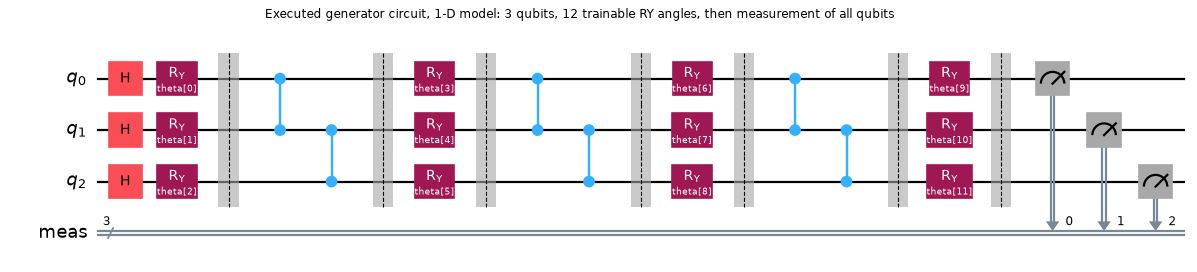

[2-D] qubits 6 | depth 27 (without measurement 26) | trainable parameters 30 | gates {'ry': 30, 'cz': 20, 'barrier': 8, 'h': 6}


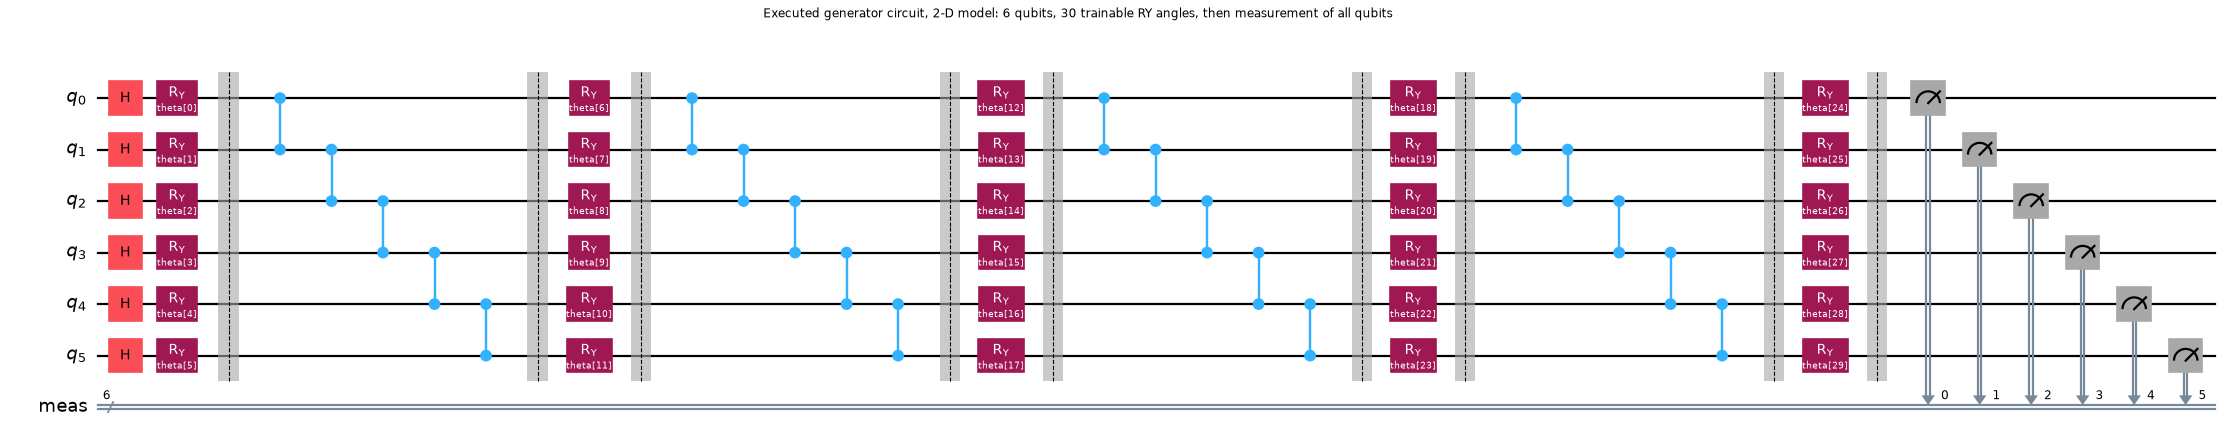

In [10]:
def build_generator(n, reps):
    qc = QuantumCircuit(n, name=f"qGAN generator ({n} qubits, r={reps})")
    qc.h(range(n))                                                             # uniform input state (paper Section IV)
    ans = n_local(n, rotation_blocks="ry", entanglement_blocks="cz", entanglement="linear", reps=reps, insert_barriers=True, parameter_prefix="theta")
    qc.compose(ans, inplace=True)
    return qc

QC = {d: build_generator(SIMS[d].n, SIMS[d].reps) for d in (1, 2)}
QC_MEAS = {d: QC[d].measure_all(inplace=False) for d in (1, 2)}
for d in (1, 2):
    c = QC_MEAS[d]
    print(f"[{d}-D] qubits {c.num_qubits} | depth {c.depth()} (without measurement {QC[d].depth()}) | trainable parameters {QC[d].num_parameters} | gates {dict(QC[d].count_ops())}")
    fig = c.draw("mpl", fold=-1)
    fig.suptitle(f"Executed generator circuit, {d}-D model: {c.num_qubits} qubits, {QC[d].num_parameters} trainable RY angles, then measurement of all qubits", fontsize=11)
    display(fig); plt.close(fig)

In [11]:
# Equivalence 1: the PyTorch simulator equals Qiskit's exact state vector (probabilities and amplitudes) for random parameters.
r_ = np.random.default_rng(SEED + 1)
for d in (1, 2):
    sim, qc = SIMS[d], QC[d]
    assert [p.name for p in qc.parameters] == [f"theta[{i}]" for i in range(sim.n_params)], "parameter order differs"
    for _ in range(5):
        th = r_.uniform(0, 2 * np.pi, sim.n_params)
        sv = Statevector(qc.assign_parameters(th))
        assert np.allclose(sim.state(torch.tensor(th)).numpy(), sv.data.real, atol=1e-12) and np.allclose(sv.data.imag, 0, atol=1e-12)
        assert np.allclose(sim.probs(torch.tensor(th)).numpy(), sv.probabilities(), atol=1e-12)
    print(f"{d}-D: simulator == Qiskit Statevector (amplitudes and probabilities, 5 random parameter sets, atol 1e-12)")

# Equivalence 2: the paper's route, SamplerQNN + TorchConnector with a shot-based Sampler.  Compare forward values and the gradient of a
# generator loss  L = sum_j p_j w_j  (fixed weights w, as the discriminator provides them) with the autograd gradient of the simulator.
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.connectors import TorchConnector
d = 1; sim, qc = SIMS[d], QC_MEAS[d]
th0 = np.random.default_rng(SEED + 2).uniform(0, 2 * np.pi, sim.n_params)
qnn = SamplerQNN(circuit=qc, input_params=[], weight_params=list(qc.parameters), sampler=StatevectorSampler(default_shots=SHOTS_CHECK, seed=SEED), sparse=False)
model = TorchConnector(qnn, initial_weights=torch.tensor(th0))
w_ = torch.tensor(np.random.default_rng(SEED + 3).uniform(0.2, 2.0, 2 ** sim.n))
out = model()                                  # TorchConnector returns the 2^n probabilities (no batch axis without inputs)
(out * w_).sum().backward()
g_qiskit = model.weight.grad.detach().numpy().copy()
t_ = torch.tensor(th0, requires_grad=True); (sim.probs(t_) * w_).sum().backward(); g_sim = t_.grad.numpy()
p_sim = sim.probs(torch.tensor(th0)).numpy()
print("max |p_qiskit - p_simulator| (shot noise, 2e5 shots):", float(np.abs(out.detach().numpy() - p_sim).max()))
print("max |grad_qiskit - grad_simulator| (parameter-shift on sampled probabilities):", float(np.abs(g_qiskit - g_sim).max()), "| gradient scale", float(np.abs(g_sim).max()))
assert np.abs(out.detach().numpy() - p_sim).max() < 5e-3 and np.abs(g_qiskit - g_sim).max() < 5e-2, "Qiskit SamplerQNN route and simulator disagree"
print("SamplerQNN + TorchConnector (the paper's implementation route) agrees with the exact simulator within shot noise.")

1-D: simulator == Qiskit Statevector (amplitudes and probabilities, 5 random parameter sets, atol 1e-12)
2-D: simulator == Qiskit Statevector (amplitudes and probabilities, 5 random parameter sets, atol 1e-12)


max |p_qiskit - p_simulator| (shot noise, 2e5 shots): 0.0010916370657897967
max |grad_qiskit - grad_simulator| (parameter-shift on sampled probabilities): 0.0002983756516171665 | gradient scale 0.16804632942146072
SamplerQNN + TorchConnector (the paper's implementation route) agrees with the exact simulator within shot noise.


In [12]:
# "O(poly(n)) gates": gate count of the generator for growing n (formula n + (r+1)n + r(n-1), r = 3), counted on the real Qiskit circuits
rows = []
for n in (3, 6, 9, 12, 15):
    c = build_generator(n, GEN_REPS)
    ops = dict(c.count_ops())
    rows.append({"qubits n": n, "grid cells 2^n": 2 ** n, "H": ops.get("h", 0), "RY": ops.get("ry", 0), "CZ": ops.get("cz", 0),
                 "total gates": sum(v for k, v in ops.items() if k != "barrier"), "formula": n + (GEN_REPS + 1) * n + GEN_REPS * (n - 1), "depth": c.depth()})
GATES = pd.DataFrame(rows); display(GATES)
assert (GATES["total gates"] == GATES["formula"]).all()

print("\nClassical discriminator (not a circuit):")
D_EXAMPLE = nn.Sequential(nn.Linear(2 ** M_QUBITS, 50), nn.LeakyReLU(0.2), nn.Linear(50, 20), nn.LeakyReLU(0.2), nn.Linear(20, 1), nn.Sigmoid())
print(D_EXAMPLE, "\ntrainable parameters (1-D problem, 8 one-hot inputs):", sum(p.numel() for p in D_EXAMPLE.parameters()), "| (2-D problem, 64 one-hot inputs):", sum(p.numel() for p in D_EXAMPLE.parameters()) + 56 * 50)

,qubits n,grid cells 2^n,H,RY,CZ,total gates,formula,depth
0,3,8,3,12,6,21,21,11
1,6,64,6,24,15,45,45,20
2,9,512,9,36,24,69,69,29
3,12,4096,12,48,33,93,93,38
4,15,32768,15,60,42,117,117,47



Classical discriminator (not a circuit):
Sequential(
  (0): Linear(in_features=8, out_features=50, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=50, out_features=20, bias=True)
  (3): LeakyReLU(negative_slope=0.2)
  (4): Linear(in_features=20, out_features=1, bias=True)
  (5): Sigmoid()
) 
trainable parameters (1-D problem, 8 one-hot inputs): 1491 | (2-D problem, 64 one-hot inputs): 4291


## 4. Training the qGAN

**Losses** (paper eq. 5). Let `x_j` be the one-hot encoding of grid cell `j` (`2^n` cells), `p_j(theta)` the generator's probabilities and `D(.)` the discriminator. In each generator step, the discriminator is first updated `N_D_STEPS = 3` times, each time on a fresh mini-batch of real training samples:

* discriminator: `L_D = BCE(D(real batch), 1) + sum_j p_j(theta) * BCE(D(x_j), 0)`: real samples should score 1, generated samples (every grid cell, weighted by how likely the generator produces it) should score 0;
* generator: `L_G = sum_j p_j(theta) * BCE(D(x_j), 1)`: the generator moves probability to the cells where the discriminator says "real".

This is exactly the Qiskit qGAN training; because the generator is exact, the "fake" sample is the whole weighted grid instead of a noisy finite sample. After every epoch (one pass over the `N_TRAIN` benign samples) we record both losses, the relative entropy `KL(target || generated)` (and, in 1-D, the Qiskit direction `KL(generated || target)`), the total-variation distance, and the maximal CDF gap (the Kolmogorov distance).

The same loop trains the classical baselines: a **softmax-probability GAN** (the generator is a vector of `2^n` logits, a classical stand-in with the same loss and the same discriminator) and an **MLP GAN** (a generator network that maps Gaussian noise to a sample in `[0, 1]^d`, rescaled to the cell-index range for the discriminator, trained with the ordinary GAN loss and the same number of discriminator updates; its distribution is estimated by binning 20,000 samples).

In [13]:
def make_disc(n_in):
    return nn.Sequential(nn.Linear(n_in, 50), nn.LeakyReLU(0.2), nn.Linear(50, 20), nn.LeakyReLU(0.2), nn.Linear(20, 1), nn.Sigmoid())   # CHOICE: Qiskit tutorial layout

class QGen(nn.Module):                         # quantum generator: exact probabilities of the RY/CZ circuit
    def __init__(self, sim, seed):
        super().__init__(); self.sim = sim
        self.theta = nn.Parameter(torch.tensor(np.random.default_rng(seed).uniform(0, 2 * np.pi, sim.n_params)))   # CHOICE: init U[0, 2 pi)
    def forward(self): return self.sim.probs(self.theta)

class SoftmaxGen(nn.Module):                   # classical probability-vector generator
    def __init__(self, k, seed):
        super().__init__(); self.logits = nn.Parameter(torch.tensor(np.random.default_rng(seed).normal(0, 0.5, k)))
    def forward(self): return torch.softmax(self.logits, 0)

def kl_div(t, g):                              # KL(target || generated); target zeros contribute nothing
    t = np.asarray(t); g = np.maximum(np.asarray(g), KL_FLOOR); m = t > 0
    return float(np.sum(t[m] * np.log(t[m] / g[m])))
def kl_rev(t, g):                              # KL(generated || target): the direction of the Qiskit tutorial (needs target > 0)
    t = np.maximum(np.asarray(t), KL_FLOOR); g = np.asarray(g); m = g > 0
    return float(np.sum(g[m] * np.log(g[m] / t[m])))
def tv_dist(t, g): return float(0.5 * np.abs(np.asarray(t) - np.asarray(g)).sum())
def marginals(p, d):
    p = np.asarray(p).reshape([NB] * d)       # axis order is reversed (last axis = feature 0), so reverse again
    return [p.sum(axis=tuple(a for a in range(d) if a != d - 1 - j)) for j in range(d)]
def ks_gap(t, g, d):                           # largest CDF gap over the feature marginals
    return max(float(np.abs(np.cumsum(a) - np.cumsum(b)).max()) for a, b in zip(marginals(t, d), marginals(g, d)))

def record(h, t, g, d):
    h["kl"].append(kl_div(t, g)); h["tv"].append(tv_dist(t, g)); h["ks"].append(ks_gap(t, g, d)); h["pmf"].append(np.asarray(g).copy())
    if d == 1: h["kl_rev"].append(kl_rev(t, g))

def new_hist():
    return {"loss_d": [], "loss_g": [], "kl": [], "kl_rev": [], "tv": [], "ks": [], "pmf": [], "time": 0.0}

def train_pmf_gan(gen, d, seed, epochs, target, train_cells):
    # qGAN / softmax GAN: both produce an exact pmf over the grid, trained with the weighted BCE losses of the paper (eq. 5).
    torch.manual_seed(seed)
    grid = GRID[d]; K = len(grid)                                           # one-hot cells
    data = grid[torch.as_tensor(train_cells)]                               # one-hot real training samples
    disc = make_disc(K)
    opt_g = torch.optim.Adam(gen.parameters(), lr=LR_G, betas=ADAM_BETAS); opt_d = torch.optim.Adam(disc.parameters(), lr=LR_D, betas=ADAM_BETAS)
    bce = nn.BCELoss(reduction="none"); ones_k, zeros_k = torch.ones(K, 1), torch.zeros(K, 1)
    h = new_hist(); t0 = time.time(); N = len(data); steps = N // BATCH
    for ep in range(epochs):
        ld_s = lg_s = 0.0
        for _ in range(steps):
            p = gen()                                                       # one forward pass serves the D updates and the G update (theta does not change in the D steps)
            for _k in range(N_D_STEPS):
                xb = data[torch.randint(0, N, (BATCH,))]
                opt_d.zero_grad()
                ld = bce(disc(xb), torch.ones(len(xb), 1)).mean() + (p.detach().reshape(-1, 1) * bce(disc(grid), zeros_k)).sum()
                ld.backward(); opt_d.step()
            opt_g.zero_grad()
            lg = (p.reshape(-1, 1) * bce(disc(grid), ones_k)).sum()
            lg.backward(); opt_g.step()
            ld_s += float(ld.detach()); lg_s += float(lg.detach())
        h["loss_d"].append(ld_s / steps); h["loss_g"].append(lg_s / steps)
        record(h, target, gen().detach().numpy(), d)
    h["time"] = time.time() - t0
    return gen, disc, h

class MLPGen(nn.Module):                       # classical sample generator
    def __init__(self, d, zdim=2):
        super().__init__(); self.zdim = zdim
        self.net = nn.Sequential(nn.Linear(zdim, 16), nn.LeakyReLU(0.2), nn.Linear(16, 16), nn.LeakyReLU(0.2), nn.Linear(16, d), nn.Sigmoid())   # CHOICE
    def forward(self, z): return self.net(z)

def binned_pmf(x, d):                          # x in [0,1]^d -> pmf over the grid cells (with +0.5 smoothing so that KL stays finite)
    b = np.clip(np.floor(x * NB).astype(int), 0, NB - 1)
    cnt = np.bincount(joint_cell(b), minlength=NB ** d).astype(float) + 0.5
    return cnt / cnt.sum()

def train_mlp_gan(d, seed, epochs, target, train_cells, n_eval=20000):
    torch.manual_seed(seed)
    data = torch.tensor(grid_coords(d)[train_cells])                        # continuous coordinates in cell-index units
    gen, disc = MLPGen(d), make_disc(d)
    opt_g = torch.optim.Adam(gen.parameters(), lr=LR_G, betas=ADAM_BETAS); opt_d = torch.optim.Adam(disc.parameters(), lr=LR_D, betas=ADAM_BETAS)
    bce = nn.BCELoss(); h = new_hist(); t0 = time.time(); N = len(data); steps = N // BATCH
    zeval = torch.tensor(np.random.default_rng(seed + 99).normal(size=(n_eval, gen.zdim)))
    to_cell_units = lambda u: u * NB - 0.5                                   # generator output in [0,1] -> cell-index coordinates (cell i = [i-0.5, i+0.5))
    for ep in range(epochs):
        ld_s = lg_s = 0.0
        for _ in range(steps):
            for _k in range(N_D_STEPS):
                xb = data[torch.randint(0, N, (BATCH,))]; fake = to_cell_units(gen(torch.randn(BATCH, gen.zdim))).detach()
                opt_d.zero_grad(); ld = bce(disc(xb), torch.ones(BATCH, 1)) + bce(disc(fake), torch.zeros(BATCH, 1)); ld.backward(); opt_d.step()
            opt_g.zero_grad(); lg = bce(disc(to_cell_units(gen(torch.randn(BATCH, gen.zdim)))), torch.ones(BATCH, 1)); lg.backward(); opt_g.step()
            ld_s += float(ld.detach()); lg_s += float(lg.detach())
        h["loss_d"].append(ld_s / steps); h["loss_g"].append(lg_s / steps)
        with torch.no_grad(): pm = binned_pmf(gen(zeval).numpy(), d)
        record(h, target, pm, d)
    h["time"] = time.time() - t0
    return gen, disc, h

def n_params(m): return sum(p.numel() for p in m.parameters())
print("parameters  qGAN 1-D:", SIMS[1].n_params, "| softmax GAN 1-D:", NB, "| MLP generator 1-D:", n_params(MLPGen(1)), "| discriminator 1-D:", n_params(make_disc(NB)), "(MLP GAN: %d)" % n_params(make_disc(1)))
print("parameters  qGAN 2-D:", SIMS[2].n_params, "| softmax GAN 2-D:", NB ** 2, "| MLP generator 2-D:", n_params(MLPGen(2)), "| discriminator 2-D:", n_params(make_disc(NB ** 2)), "(MLP GAN: %d)" % n_params(make_disc(2)))

parameters  qGAN 1-D: 12 | softmax GAN 1-D: 8 | MLP generator 1-D: 337 | discriminator 1-D: 1491 (MLP GAN: 1141)
parameters  qGAN 2-D: 30 | softmax GAN 2-D: 64 | MLP generator 2-D: 354 | discriminator 2-D: 4291 (MLP GAN: 1191)


### 4.1 How well can the circuit do at all? The expressivity floor

A GAN cannot be better than the best distribution the generator can represent. As a reference, the next cell fits the circuit parameters directly by minimising `KL(target || p_theta)` with L-BFGS from 8 random starts (this uses the target distribution, so it is a *bound*, not a training method). The 3-qubit generator should be able to load the 1-D target almost exactly; the 6-qubit generator with 30 real parameters cannot represent a general 64-cell distribution (63 free values), so a floor above zero is expected there.

In [14]:
def expressivity_floor(sim, target, starts=8):
    tt = torch.tensor(target); m = tt > 0; best = np.inf
    for st in range(starts):
        th = nn.Parameter(torch.tensor(np.random.default_rng(1000 + st).uniform(0, 2 * np.pi, sim.n_params)))
        opt = torch.optim.LBFGS([th], lr=1, max_iter=300, line_search_fn="strong_wolfe")
        def closure():
            opt.zero_grad(); p = sim.probs(th); loss = (tt[m] * torch.log(tt[m] / p[m].clamp_min(1e-12))).sum(); loss.backward(); return loss
        opt.step(closure); best = min(best, float(closure().detach()))
    return best
FLOOR = {1: expressivity_floor(SIMS[1], TARGET[1]), 2: expressivity_floor(SIMS[2], TARGET[2])}
print("smallest KL(target || p_theta) reachable by the 3-qubit generator: %.4f | by the 6-qubit generator: %.4f" % (FLOOR[1], FLOOR[2]))

smallest KL(target || p_theta) reachable by the 3-qubit generator: 0.0005 | by the 6-qubit generator: 0.5291


## 5. Main experiment: one feature, three qubits, four initialisations

Each initialisation (seed) draws its own `N_TRAIN` benign training flows from the benign pool, its own initial generator angles and its own discriminator weights. All three generators (quantum, softmax, MLP) see the **same** training samples for a given seed; the qGAN and the softmax GAN also share the discriminator design (one-hot input), the MLP GAN needs one on the continuous coordinate. As a floor for the relative entropy we also print the `KL` of the empirical histogram of the `N_TRAIN` training samples itself: no model fitted to those samples can be expected to be much closer to the pool's target than that.

In [15]:
RUNS = {"qGAN": {}, "softmax GAN": {}, "MLP GAN": {}}
TRAIN_SAMPLES = {}
for seed in SEEDS_1D:
    r_s = np.random.default_rng(seed)
    tc = CELL_TR[1][r_s.choice(BEN_POOL, N_TRAIN, replace=False)]                                  # N_TRAIN benign training samples (cell ids)
    TRAIN_SAMPLES[seed] = tc
    g, dsc, h = train_pmf_gan(QGen(SIMS[1], seed), 1, seed, EPOCHS, TARGET[1], tc); RUNS["qGAN"][seed] = (g, dsc, h)
    g2, d2, h2 = train_pmf_gan(SoftmaxGen(NB, seed), 1, seed, EPOCHS, TARGET[1], tc); RUNS["softmax GAN"][seed] = (g2, d2, h2)
    g3, d3, h3 = train_mlp_gan(1, seed, EPOCHS, TARGET[1], tc); RUNS["MLP GAN"][seed] = (g3, d3, h3)
    floor = kl_div(TARGET[1], np.bincount(tc, minlength=NB) / len(tc) + 1e-12)
    print(f"seed {seed}: KL after epoch 1 / {E_HALF} / {EPOCHS}:  qGAN {h['kl'][0]:.3f} / {h['kl'][E_HALF-1]:.3f} / {h['kl'][-1]:.3f}  ({h['time']:.0f} s)"
          f" | softmax {h2['kl'][0]:.3f} / {h2['kl'][E_HALF-1]:.3f} / {h2['kl'][-1]:.3f}"
          f" | MLP {h3['kl'][0]:.3f} / {h3['kl'][E_HALF-1]:.3f} / {h3['kl'][-1]:.3f} | sample-histogram floor {floor:.4f}", flush=True)

seed 42: KL after epoch 1 / 50 / 100:  qGAN 0.510 / 0.022 / 0.021  (72 s) | softmax 0.379 / 0.012 / 0.013 | MLP 0.451 / 0.041 / 0.053 | sample-histogram floor 0.0104


seed 43: KL after epoch 1 / 50 / 100:  qGAN 0.109 / 0.010 / 0.008  (69 s) | softmax 0.279 / 0.002 / 0.002 | MLP 0.351 / 0.010 / 0.047 | sample-histogram floor 0.0015


seed 44: KL after epoch 1 / 50 / 100:  qGAN 1.556 / 0.024 / 0.017  (70 s) | softmax 0.530 / 0.011 / 0.012 | MLP 0.216 / 0.108 / 0.018 | sample-histogram floor 0.0105


seed 45: KL after epoch 1 / 50 / 100:  qGAN 0.085 / 0.015 / 0.011  (72 s) | softmax 0.153 / 0.007 / 0.005 | MLP 0.604 / 0.030 / 0.007 | sample-histogram floor 0.0048


### 5.1 Re-drawing the paper's Figure 4: losses and relative entropy

Left: generator and discriminator loss per epoch for the first initialisation (paper Fig. 4, left). Right: the relative entropy between the generated and the target distribution for every initialisation (paper Fig. 4, right: "for the various initializations ... over 50 training epochs as well as 100 training epochs"). The dotted vertical line marks the 50-epoch point.

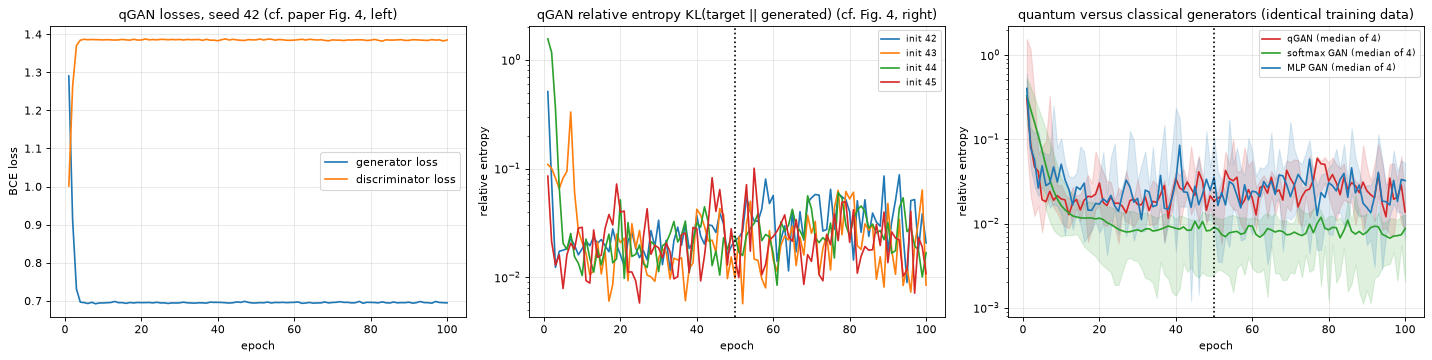

In [16]:
s0 = SEEDS_1D[0]; h0 = RUNS["qGAN"][s0][2]; ep_ax = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].plot(ep_ax, h0["loss_g"], label="generator loss"); ax[0].plot(ep_ax, h0["loss_d"], label="discriminator loss")
ax[0].set_title(f"qGAN losses, seed {s0} (cf. paper Fig. 4, left)"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE loss"); ax[0].legend()
for seed in SEEDS_1D:
    ax[1].plot(ep_ax, RUNS["qGAN"][seed][2]["kl"], label=f"init {seed}")
ax[1].axvline(E_HALF, c="k", ls=":"); ax[1].set_yscale("log"); ax[1].set_title("qGAN relative entropy KL(target || generated) (cf. Fig. 4, right)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("relative entropy"); ax[1].legend(fontsize=8)
for name, c in [("qGAN", "tab:red"), ("softmax GAN", "tab:green"), ("MLP GAN", "tab:blue")]:
    A = np.array([RUNS[name][s][2]["kl"] for s in SEEDS_1D])
    ax[2].plot(ep_ax, np.median(A, 0), c=c, label=f"{name} (median of {len(SEEDS_1D)})"); ax[2].fill_between(ep_ax, A.min(0), A.max(0), color=c, alpha=0.15)
ax[2].set_yscale("log"); ax[2].axvline(E_HALF, c="k", ls=":"); ax[2].set_title("quantum versus classical generators (identical training data)")
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("relative entropy"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.2 Re-drawing the paper's Figure 5: CDF of generated versus real data

The cumulative distribution function over the 8 grid cells for the target (full benign pool), the qGAN after 50 epochs and after 100 epochs (first initialisation), and the difference between generated and true CDF.

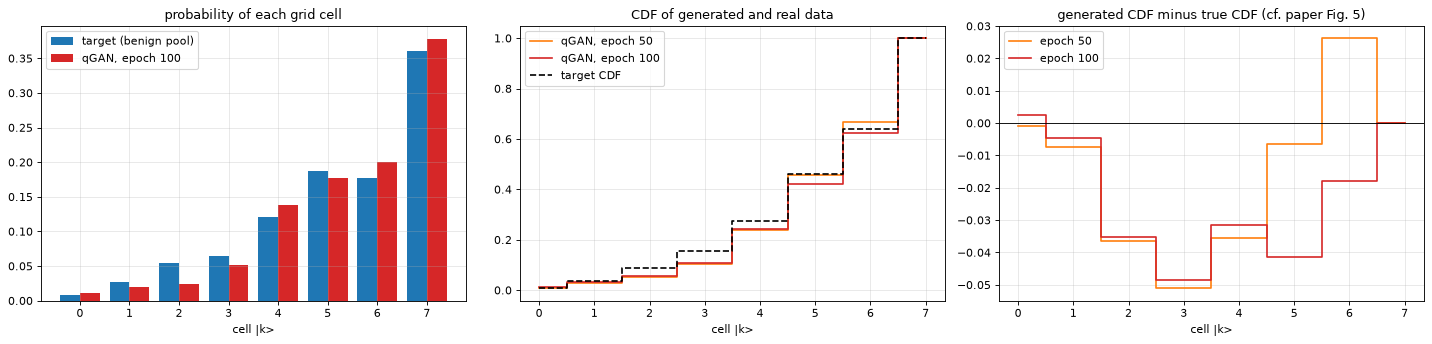

In [17]:
cdf_t = np.cumsum(TARGET[1]); xs = np.arange(NB)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
ax[0].bar(xs - 0.2, TARGET[1], 0.4, label="target (benign pool)", color="tab:blue")
ax[0].bar(xs + 0.2, RUNS["qGAN"][s0][2]["pmf"][-1], 0.4, label=f"qGAN, epoch {EPOCHS}", color="tab:red"); ax[0].set_title("probability of each grid cell"); ax[0].set_xlabel("cell |k>"); ax[0].legend()
for e, c in [(E_HALF, "tab:orange"), (EPOCHS, "tab:red")]:
    ax[1].step(xs, np.cumsum(RUNS["qGAN"][s0][2]["pmf"][e - 1]), where="mid", c=c, label=f"qGAN, epoch {e}")
    ax[2].step(xs, np.cumsum(RUNS["qGAN"][s0][2]["pmf"][e - 1]) - cdf_t, where="mid", c=c, label=f"epoch {e}")
ax[1].step(xs, cdf_t, where="mid", c="k", ls="--", label="target CDF"); ax[1].set_title("CDF of generated and real data"); ax[1].set_xlabel("cell |k>"); ax[1].legend()
ax[2].axhline(0, c="k", lw=0.8); ax[2].set_title("generated CDF minus true CDF (cf. paper Fig. 5)"); ax[2].set_xlabel("cell |k>"); ax[2].legend()
plt.tight_layout(); plt.show()

### 5.3 Numbers behind the figures

In [18]:
def summarise(name, runs, seeds):
    H = [runs[s][2] for s in seeds]
    f = lambda key, e: np.array([h[key][e - 1] for h in H])
    r = {"model": name, "KL epoch 1": f("kl", 1).mean()}
    for e in (E_HALF, EPOCHS):
        r[f"KL @{e}"] = f("kl", e).mean(); r[f"KL @{e} std"] = f("kl", e).std()
    r[f"TV @{EPOCHS}"] = f("tv", EPOCHS).mean(); r[f"CDF gap @{E_HALF}"] = f("ks", E_HALF).mean(); r[f"CDF gap @{EPOCHS}"] = f("ks", EPOCHS).mean()
    r["train time/run (s)"] = np.mean([h["time"] for h in H])
    return r
SUM1 = pd.DataFrame([summarise(n, RUNS[n], SEEDS_1D) for n in RUNS]).set_index("model")
display(SUM1.round(4))
print("qGAN per initialisation (KL @ epoch 1 / %d / %d, Qiskit-direction KL(gen||target) @ %d, max CDF gap @ %d / %d):" % (E_HALF, EPOCHS, EPOCHS, E_HALF, EPOCHS))
for s in SEEDS_1D:
    h = RUNS["qGAN"][s][2]
    print(f"  init {s}: {h['kl'][0]:.3f} / {h['kl'][E_HALF-1]:.4f} / {h['kl'][-1]:.4f} | {h['kl_rev'][-1]:.4f} | {h['ks'][E_HALF-1]:.4f} / {h['ks'][-1]:.4f}")

,KL epoch 1,KL @50,KL @50 std,KL @100,KL @100 std,TV @100,CDF gap @50,CDF gap @100,train time/run (s)
model,,,,,,,,,
qGAN,0.5652,0.0177,0.0057,0.0142,0.0048,0.0492,0.0413,0.0365,70.6553
softmax GAN,0.3352,0.0082,0.0037,0.0080,0.0045,0.0445,0.0326,0.0302,45.2933
MLP GAN,0.4056,0.0471,0.0367,0.0311,0.0193,0.0885,0.0792,0.0640,54.9911


qGAN per initialisation (KL @ epoch 1 / 50 / 100, Qiskit-direction KL(gen||target) @ 100, max CDF gap @ 50 / 100):
  init 42: 0.510 / 0.0221 / 0.0207 | 0.0171 | 0.0510 / 0.0485
  init 43: 0.109 / 0.0098 / 0.0085 | 0.0092 | 0.0115 / 0.0289
  init 44: 1.556 / 0.0240 / 0.0168 | 0.0186 | 0.0523 / 0.0300
  init 45: 0.085 / 0.0149 / 0.0108 | 0.0092 | 0.0505 / 0.0385


## 6. Extension: two features, six qubits

The paper's Fig. 2 shows an `n`-qubit generator; the Qiskit qGAN supports several features by giving each its own register. Here PC1 and PC2 are loaded jointly: 6 qubits, 64 grid cells (feature 0 on qubits 0-2, feature 1 on qubits 3-5), a 30-parameter generator and a 2-input discriminator. The `CZ` chain links the two registers, so correlations between the features can be represented. The classical baselines are the 64-logit softmax GAN and the 2-D MLP GAN.

seed 42: KL after epoch 1 / 60:  qGAN 1.808 / 3.367 (67 s) | softmax 1.671 / 0.048 | MLP 3.534 / 0.328


seed 43: KL after epoch 1 / 60:  qGAN 2.441 / 2.056 (68 s) | softmax 1.558 / 0.031 | MLP 2.153 / 5.604


,KL epoch 1,KL @60,TV @60,marginal CDF gap @60
model,,,,
qGAN,2.1244,2.7115,0.5630,0.4487
softmax GAN,1.6148,0.0397,0.0664,0.0373
MLP GAN,2.8434,2.9659,0.4220,0.3622


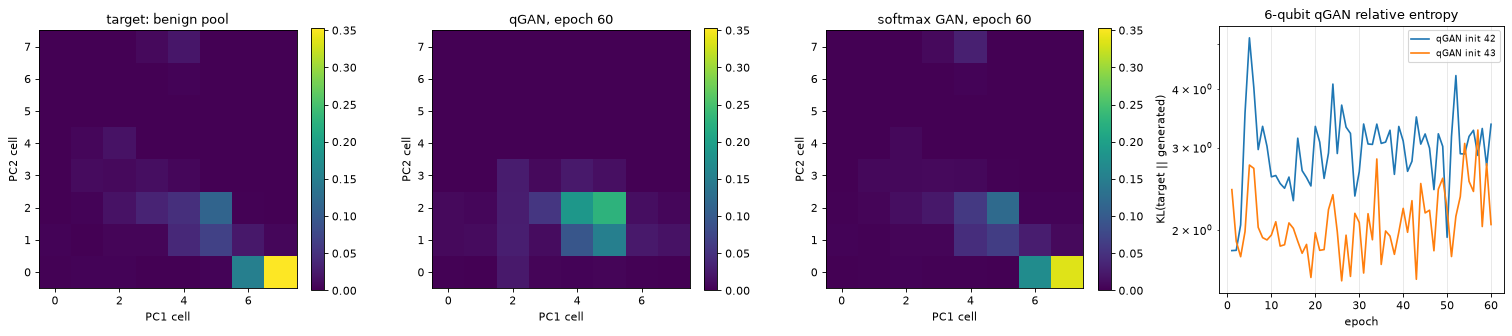

In [19]:
RUNS2 = {"qGAN": {}, "softmax GAN": {}, "MLP GAN": {}}
for seed in SEEDS_2D:
    tc = CELL_TR[2][np.random.default_rng(seed).choice(BEN_POOL, N_TRAIN, replace=False)]
    TRAIN_SAMPLES[("2d", seed)] = tc
    RUNS2["qGAN"][seed] = train_pmf_gan(QGen(SIMS[2], seed), 2, seed, EPOCHS_2D, TARGET[2], tc)
    RUNS2["softmax GAN"][seed] = train_pmf_gan(SoftmaxGen(NB ** 2, seed), 2, seed, EPOCHS_2D, TARGET[2], tc)
    RUNS2["MLP GAN"][seed] = train_mlp_gan(2, seed, EPOCHS_2D, TARGET[2], tc)
    print(f"seed {seed}: KL after epoch 1 / {EPOCHS_2D}:  qGAN {RUNS2['qGAN'][seed][2]['kl'][0]:.3f} / {RUNS2['qGAN'][seed][2]['kl'][-1]:.3f} ({RUNS2['qGAN'][seed][2]['time']:.0f} s)"
          f" | softmax {RUNS2['softmax GAN'][seed][2]['kl'][0]:.3f} / {RUNS2['softmax GAN'][seed][2]['kl'][-1]:.3f}"
          f" | MLP {RUNS2['MLP GAN'][seed][2]['kl'][0]:.3f} / {RUNS2['MLP GAN'][seed][2]['kl'][-1]:.3f}", flush=True)
SUM2 = pd.DataFrame([{"model": n, "KL epoch 1": np.mean([RUNS2[n][s][2]["kl"][0] for s in SEEDS_2D]), f"KL @{EPOCHS_2D}": np.mean([RUNS2[n][s][2]["kl"][-1] for s in SEEDS_2D]),
                      f"TV @{EPOCHS_2D}": np.mean([RUNS2[n][s][2]["tv"][-1] for s in SEEDS_2D]), f"marginal CDF gap @{EPOCHS_2D}": np.mean([RUNS2[n][s][2]["ks"][-1] for s in SEEDS_2D])} for n in RUNS2]).set_index("model")
display(SUM2.round(4))

s2 = SEEDS_2D[0]
to_img = lambda p: np.asarray(p).reshape(NB, NB)           # row = feature 1, column = feature 0 (k = b0 + 8 b1)
fig, ax = plt.subplots(1, 4, figsize=(19, 4.3))
vmax = TARGET[2].max()
for a, (p, ttl) in zip(ax[:3], [(TARGET[2], "target: benign pool"), (RUNS2["qGAN"][s2][2]["pmf"][-1], f"qGAN, epoch {EPOCHS_2D}"), (RUNS2["softmax GAN"][s2][2]["pmf"][-1], f"softmax GAN, epoch {EPOCHS_2D}")]):
    im = a.imshow(to_img(p), origin="lower", vmin=0, vmax=vmax, cmap="viridis"); a.set_title(ttl); a.set_xlabel("PC1 cell"); a.set_ylabel("PC2 cell"); a.grid(False); plt.colorbar(im, ax=a, fraction=0.046)
for seed in SEEDS_2D: ax[3].plot(np.arange(1, EPOCHS_2D + 1), RUNS2["qGAN"][seed][2]["kl"], label=f"qGAN init {seed}")
ax[3].set_yscale("log"); ax[3].set_xlabel("epoch"); ax[3].set_ylabel("KL(target || generated)"); ax[3].set_title("6-qubit qGAN relative entropy"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Extra: using the trained generator for intrusion detection

The paper's title and conclusion promise an *intrusion detection system*, but it reports no detection result. A generative model can be used as a detector in two standard ways, both tried here with the generators of Sections 5 and 6:

* **One-class (unsupervised) density score.** The generator has loaded the distribution of benign traffic, so a flow that falls in a cell with a small generated probability is suspicious: `score = -log p_G(cell(flow))`. Only benign flows were used for training. The decision threshold is the 95th percentile of the scores of 2000 benign validation flows (so about 5 % false positives by construction).
* **Two generators and a likelihood ratio (supervised, uses attack labels).** A second qGAN is trained on attack flows of the training split; `score = log p_attack(cell) - log p_benign(cell)`.

Everything is compared with classical detectors trained on the **identical inputs**: the integer grid cell(s) that the generator sees (`cell`), the continuous PCA coordinates (`PCs`), and all 122 preprocessed columns (`all`): Isolation Forest and a one-class SVM (benign flows only), and a Random Forest (supervised, 30,000 labelled training flows). A "histogram (oracle)" row uses the true benign (or attack) cell frequencies, i.e. what a perfect generator of that grid could do. Test sets: the 20 % hold-out of `KDDTrain+` (same attack types as in training) and `KDDTest+` (unseen attack types). Thresholds are always set on benign validation flows, never on a test set.

In [20]:
Y_HO, Y_TE = y_all[HO], RAW_TE.y.values
def det_metrics(s_val, s_ho, s_te):
    thr = np.quantile(s_val, 1 - BENIGN_FPR); out = {}
    for tag, s, y in [("HO", s_ho, Y_HO), ("TE", s_te, Y_TE)]:
        pred = (s > thr).astype(int)
        out.update({f"AUC {tag}": roc_auc_score(y, s), f"F1 {tag}": f1_score(y, pred), f"recall {tag}": recall_score(y, pred),
                    f"precision {tag}": precision_score(y, pred, zero_division=0), f"FPR {tag}": float(pred[y == 0].mean()), f"acc {tag}": accuracy_score(y, pred)})
    return out
def pmf_score(pmf, cells): return -np.log(np.maximum(pmf, 1e-6)[cells])
def llr_score(p_att, p_ben, cells): return np.log(np.maximum(p_att, 1e-6)[cells]) - np.log(np.maximum(p_ben, 1e-6)[cells])

ROWS = []
def add(method, inputs, kind, seed, s_val, s_ho, s_te):
    ROWS.append({"method": method, "inputs": inputs, "kind": kind, "seed": seed, **det_metrics(s_val, s_ho, s_te)})

# --- generator-based detectors (1-D and 2-D) -------------------------------------------------------
for d, runs, seeds, tag in [(1, RUNS, SEEDS_1D, "cell PC1"), (2, RUNS2, SEEDS_2D, "cells PC1,PC2")]:
    cv, ch, ct = CELL_TR[d][BEN_VAL], CELL_TR[d][HO], CELL_TE[d]
    for name in ["qGAN", "softmax GAN", "MLP GAN"]:
        for s in seeds:
            pm = runs[name][s][2]["pmf"][-1]
            add(name + f" density ({d}-D)", tag, "one-class", s, pmf_score(pm, cv), pmf_score(pm, ch), pmf_score(pm, ct))
    add(f"histogram oracle ({d}-D)", tag, "one-class", 0, pmf_score(TARGET[d], cv), pmf_score(TARGET[d], ch), pmf_score(TARGET[d], ct))
    add(f"histogram LLR oracle ({d}-D)", tag, "supervised", 0, llr_score(ATT_TARGET[d], TARGET[d], cv), llr_score(ATT_TARGET[d], TARGET[d], ch), llr_score(ATT_TARGET[d], TARGET[d], ct))

# --- two qGANs (attack class and benign class) and the likelihood ratio, 1-D ------------------------
ATT_RUNS = {}
for seed in SEEDS_ATT:
    tc = CELL_TR[1][np.random.default_rng(seed).choice(ATT_POOL, N_TRAIN, replace=False)]
    ATT_RUNS[seed] = train_pmf_gan(QGen(SIMS[1], seed), 1, seed, EPOCHS, ATT_TARGET[1], tc)
    pa, pb = ATT_RUNS[seed][2]["pmf"][-1], RUNS["qGAN"][seed][2]["pmf"][-1]
    cv, ch, ct = CELL_TR[1][BEN_VAL], CELL_TR[1][HO], CELL_TE[1]
    add("qGAN pair LLR (1-D)", "cell PC1", "supervised", seed, llr_score(pa, pb, cv), llr_score(pa, pb, ch), llr_score(pa, pb, ct))
    print(f"attack-class qGAN seed {seed}: KL(attack target || generated) epoch 1 -> {EPOCHS}: {ATT_RUNS[seed][2]['kl'][0]:.3f} -> {ATT_RUNS[seed][2]['kl'][-1]:.3f}", flush=True)

attack-class qGAN seed 42: KL(attack target || generated) epoch 1 -> 100: 4.810 -> 0.173


attack-class qGAN seed 43: KL(attack target || generated) epoch 1 -> 100: 0.541 -> 0.199


In [21]:
# --- classical detectors on identical inputs ---------------------------------------------------------
rs_ = np.random.default_rng(SEED)
RF_IDX = rs_.choice(TR_ALL, min(30000, len(TR_ALL)), replace=False)
OC_IDX = BEN_POOL[:5000]
INPUTS = {   # name -> (matrix for RAW_TR rows, matrix for KDDTest+ rows)
    "cell PC1":       (feat_bins(PC_TR, 1).astype(float), feat_bins(PC_TE, 1).astype(float)),
    "PC1 (continuous)": (PC_TR[:, :1], PC_TE[:, :1]),
    "cells PC1,PC2":  (feat_bins(PC_TR, 2).astype(float), feat_bins(PC_TE, 2).astype(float)),
    "PC1,PC2 (continuous)": (PC_TR[:, :2], PC_TE[:, :2]),
    "all 122 columns": (FULL_TR, FULL_TE),
}
for iname, (Xtr, Xte) in INPUTS.items():
    t0 = time.time()
    iso = IsolationForest(n_estimators=100, random_state=SEED).fit(Xtr[BEN_POOL])
    f = lambda X: -iso.decision_function(X)
    add("Isolation Forest", iname, "one-class", SEED, f(Xtr[BEN_VAL]), f(Xtr[HO]), f(Xte))
    oc = OneClassSVM(gamma="scale", nu=0.05).fit(Xtr[OC_IDX])
    f = lambda X: -oc.decision_function(X)
    add("One-class SVM (rbf)", iname, "one-class", SEED, f(Xtr[BEN_VAL]), f(Xtr[HO]), f(Xte))
    rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(Xtr[RF_IDX], y_all[RF_IDX])
    f = lambda X: rf.predict_proba(X)[:, 1]
    add("Random Forest (supervised)", iname, "supervised", SEED, f(Xtr[BEN_VAL]), f(Xtr[HO]), f(Xte))
    print(f"{iname}: classical detectors fitted in {time.time()-t0:.0f} s", flush=True)

DET = pd.DataFrame(ROWS)
metric_cols = [c for c in DET.columns if c not in ("method", "inputs", "kind", "seed")]
AGG = DET.groupby(["method", "inputs", "kind"], sort=False)[metric_cols].agg(["mean", "std"])
AGG_MEAN = DET.groupby(["method", "inputs", "kind"], sort=False)[metric_cols].mean()
AGG_MEAN["n runs"] = DET.groupby(["method", "inputs", "kind"], sort=False).size()
show_cols = ["AUC HO", "AUC TE", "F1 HO", "recall HO", "FPR HO", "F1 TE", "recall TE", "FPR TE", "n runs"]
display(AGG_MEAN[show_cols].round(3))
std_q = DET[DET.method == "qGAN density (1-D)"][["AUC HO", "AUC TE"]].std()
print("spread over the initialisations, qGAN density (1-D): std of AUC HO %.3f, of AUC TE %.3f" % (std_q["AUC HO"], std_q["AUC TE"]))

cell PC1: classical detectors fitted in 2 s


PC1 (continuous): classical detectors fitted in 5 s


cells PC1,PC2: classical detectors fitted in 2 s


PC1,PC2 (continuous): classical detectors fitted in 4 s


all 122 columns: classical detectors fitted in 6 s


,,,AUC HO,AUC TE,F1 HO,recall HO,FPR HO,F1 TE,recall TE,FPR TE,n runs
method,inputs,kind,,,,,,,,,
qGAN density (1-D),cell PC1,one-class,0.930,0.906,0.881,0.818,0.034,0.728,0.583,0.027,4
softmax GAN density (1-D),cell PC1,one-class,0.933,0.901,0.881,0.818,0.034,0.728,0.583,0.027,4
MLP GAN density (1-D),cell PC1,one-class,0.936,0.907,0.881,0.818,0.034,0.728,0.583,0.027,4
histogram oracle (1-D),cell PC1,one-class,0.932,0.895,0.881,0.818,0.034,0.728,0.583,0.027,1
histogram LLR oracle (1-D),cell PC1,supervised,0.943,0.886,0.881,0.818,0.034,0.728,0.583,0.027,1
qGAN density (2-D),"cells PC1,PC2",one-class,0.671,0.635,0.000,0.000,0.000,0.000,0.000,0.000,2
softmax GAN density (2-D),"cells PC1,PC2",one-class,0.938,0.922,0.885,0.836,0.046,0.761,0.626,0.025,2
MLP GAN density (2-D),"cells PC1,PC2",one-class,0.707,0.633,0.161,0.102,0.027,0.277,0.192,0.004,2
histogram oracle (2-D),"cells PC1,PC2",one-class,0.937,0.923,0.882,0.831,0.047,0.769,0.636,0.023,1


spread over the initialisations, qGAN density (1-D): std of AUC HO 0.012, of AUC TE 0.017


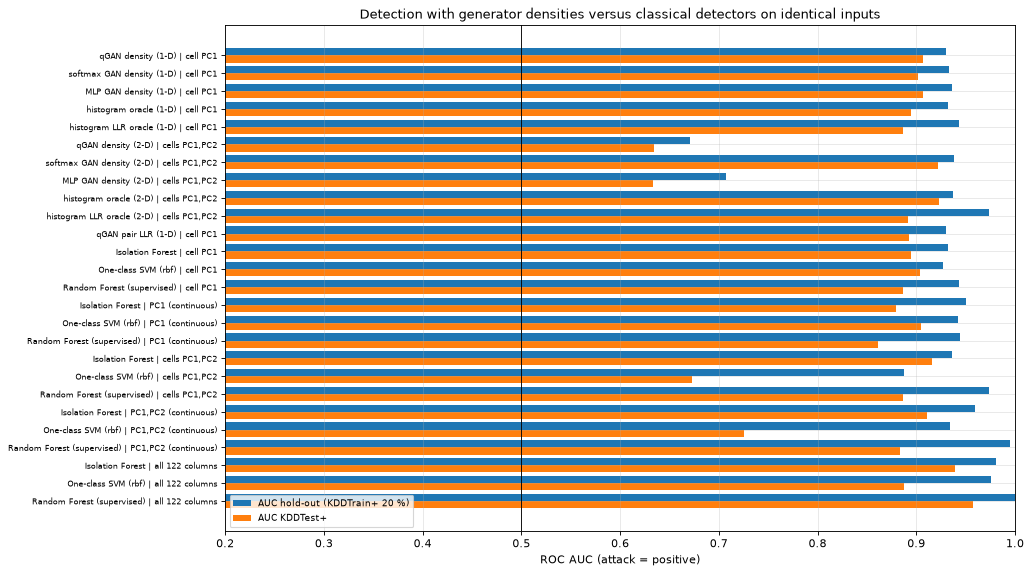

In [22]:
sel = AGG_MEAN.reset_index()
fig, ax = plt.subplots(figsize=(13, max(5, 0.28 * len(sel))))
yy = np.arange(len(sel))
ax.barh(yy - 0.2, sel["AUC HO"], 0.4, label="AUC hold-out (KDDTrain+ 20 %)", color="tab:blue")
ax.barh(yy + 0.2, sel["AUC TE"], 0.4, label="AUC KDDTest+", color="tab:orange")
ax.set_yticks(yy); ax.set_yticklabels([f"{m} | {i}" for m, i in zip(sel.method, sel.inputs)], fontsize=7); ax.invert_yaxis()
ax.axvline(0.5, c="k", lw=0.8); ax.set_xlim(0.2, 1.0); ax.set_xlabel("ROC AUC (attack = positive)"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Detection with generator densities versus classical detectors on identical inputs")
plt.tight_layout(); plt.show()

## 8. Paper versus this notebook: claim by claim

The paper contains **no numerical result** (no table, no accuracy, no relative-entropy value), only the qualitative behaviour in Figures 4 and 5 and the claims of the abstract and conclusion. Each claim is therefore turned into a stated, checkable criterion (our choice, fixed here before reading the numbers of the final run) and answered with one of *reproduced*, *not reached*, or *cannot be checked*. Where the paper has no claim at all, the line is marked *extra*.

In [23]:
Hq = [RUNS["qGAN"][s][2] for s in SEEDS_1D]
kl1  = np.array([h["kl"][0] for h in Hq]); klh = np.array([h["kl"][E_HALF - 1] for h in Hq]); klf = np.array([h["kl"][-1] for h in Hq])
ksh  = np.array([h["ks"][E_HALF - 1] for h in Hq]); ksf = np.array([h["ks"][-1] for h in Hq])
dl_end = np.mean([np.mean(h["loss_d"][-10:]) for h in Hq]); gl_end = np.mean([np.mean(h["loss_g"][-10:]) for h in Hq])
cl_f = {n: np.array([RUNS[n][s][2]["kl"][-1] for s in SEEDS_1D]) for n in ("softmax GAN", "MLP GAN")}
auc_q = DET[DET.method == "qGAN density (1-D)"]["AUC HO"].mean()

V = lambda ok: "reproduced" if ok else "not reached"
claims = [
 ("Fig. 4 left: generator and discriminator losses evolve during training (adversarial game)", "curves shown, no values",
  f"D loss (last 10 epochs, mean over inits) {dl_end:.3f} (equilibrium value 2 ln 2 = 1.386); G loss {gl_end:.3f}",
  V(np.isfinite(dl_end) and abs(dl_end - 2 * np.log(2)) < 0.25) + " (criterion: D loss within 0.25 of 2 ln 2)"),
 (f"Fig. 4 right: relative entropy falls and converges for every initialisation, at {E_HALF} and at {EPOCHS} epochs", "curves shown, no values",
  f"KL epoch 1: {kl1.mean():.2f}; KL @{E_HALF}: {klh.mean():.3f} (max {klh.max():.3f}); KL @{EPOCHS}: {klf.mean():.3f} (max {klf.max():.3f})",
  V((klf < kl1).all() and (klh < kl1).all() and np.median(klf) < C_KL_REL * np.median(kl1)) + f" (criterion: every init below its epoch-1 value and median KL @{EPOCHS} < {C_KL_REL} x median epoch-1 KL; the circuit's own floor is {FLOOR[1]:.4f})"),
 (f"Fig. 5: CDF of generated data approaches the real CDF (difference small after {E_HALF} / {EPOCHS} epochs)", "curves shown, no values",
  f"max CDF gap @{E_HALF}: {ksh.mean():.3f} (max {ksh.max():.3f}); @{EPOCHS}: {ksf.mean():.3f} (max {ksf.max():.3f})",
  V(np.median(ksf) < C_KS) + f" (criterion: median max-CDF-gap @{EPOCHS} < {C_KS})"),
 ("Generator needs O(poly(n)) gates (abstract)", "stated, not shown",
  "gate count = n + (r+1)n + r(n-1) for n = 3..15, verified on the Qiskit circuits (Section 3)", V((GATES["total gates"] == GATES["formula"]).all())),
 ("Runs without a quantum computer, on a classical simulator", "Colab, Qiskit + PyTorch",
  f"yes: exact PyTorch simulator, equal to Qiskit Statevector and to SamplerQNN + TorchConnector; {EPOCHS} epochs took {np.mean([h['time'] for h in Hq])/60:.1f} min per init", "reproduced"),
 ("The qGAN 'can detect attack packets' (abstract, conclusion)", "no detection metric",
  f"extra: qGAN density score (1-D, one feature) has AUC {auc_q:.3f} on the hold-out; see Section 7 for all detectors", "cannot be checked (paper reports no detection result)"),
 ("Quantum may 'outperform' classical ML (abstract)", "no comparison",
  f"extra: KL @{EPOCHS} qGAN {klf.mean():.3f} vs softmax GAN {cl_f['softmax GAN'].mean():.3f} vs MLP GAN {cl_f['MLP GAN'].mean():.3f}; detection AUC in Section 7",
  "cannot be checked (no comparison in the paper); here " + ("the qGAN reaches the lowest KL" if klf.mean() < min(v.mean() for v in cl_f.values()) else "a classical generator is at least as close")),
]
VERDICTS = pd.DataFrame(claims, columns=["Claim of the paper", "Paper value", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 200)
display(VERDICTS)

,Claim of the paper,Paper value,This notebook,Verdict
0,Fig. 4 left: generator and discriminator losses evolve during training (adversarial game),"curves shown, no values","D loss (last 10 epochs, mean over inits) 1.384 (equilibrium value 2 ln 2 = 1.386); G loss 0.697",reproduced (criterion: D loss within 0.25 of 2 ln 2)
1,"Fig. 4 right: relative entropy falls and converges for every initialisation, at 50 and at 100 epochs","curves shown, no values",KL epoch 1: 0.57; KL @50: 0.018 (max 0.024); KL @100: 0.014 (max 0.021),reproduced (criterion: every init below its epoch-1 value and median KL @100 < 0.25 x median epoch-1 KL; the circuit's own floor is 0.0005)
2,Fig. 5: CDF of generated data approaches the real CDF (difference small after 50 / 100 epochs),"curves shown, no values",max CDF gap @50: 0.041 (max 0.052); @100: 0.036 (max 0.049),reproduced (criterion: median max-CDF-gap @100 < 0.1)
3,Generator needs O(poly(n)) gates (abstract),"stated, not shown","gate count = n + (r+1)n + r(n-1) for n = 3..15, verified on the Qiskit circuits (Section 3)",reproduced
4,"Runs without a quantum computer, on a classical simulator","Colab, Qiskit + PyTorch","yes: exact PyTorch simulator, equal to Qiskit Statevector and to SamplerQNN + TorchConnector; 100 epochs took 1.2 min per init",reproduced
5,"The qGAN 'can detect attack packets' (abstract, conclusion)",no detection metric,"extra: qGAN density score (1-D, one feature) has AUC 0.930 on the hold-out; see Section 7 for all detectors",cannot be checked (paper reports no detection result)
6,Quantum may 'outperform' classical ML (abstract),no comparison,extra: KL @100 qGAN 0.014 vs softmax GAN 0.008 vs MLP GAN 0.031; detection AUC in Section 7,cannot be checked (no comparison in the paper); here a classical generator is at least as close


## 9. Reading the paper critically

*(Written after the final run; the numbers are those printed above.)*

1. **The paper contains no result that can be compared numerically.** Figures 4 and 5 are qualitative, and the abstract and conclusion claim that the qGAN "can detect attack packets" and may "outperform" classical machine learning without a detection metric or a classical baseline. What can be checked is the behaviour of the qGAN itself: with the circuit family of the paper (`H`, `RY`, linear `CZ`), a classical neural-network discriminator and Adam, the relative entropy to the benign-traffic distribution falls from 0.57 (mean after epoch 1) to 0.014 (all four initialisations between 0.008 and 0.021), the CDF gap is 0.036 and the discriminator loss settles at the equilibrium value 2 ln 2. That part is reproduced for the one-feature, 3-qubit setting that the notebook had to choose, because the paper does not say which NSL-KDD features were used or how many qubits.
2. **Training is delicate and the paper hides it.** With one discriminator update per generator update, equal learning rates and the raw cell index as discriminator input, the discriminator output sat at 0.5 and the generator drifted without useful signal (relative entropy 0.1-0.7, not decreasing). It needed a slow generator, three discriminator updates per step and a one-hot input. The pilot runs that found this used the target distribution as a diagnostic (not test data), but they are tuning, and the paper reports none of it. Fig. 4 of the paper therefore says little unless its learning rates, batch size and discriminator input are known.
3. **No quantum advantage is visible.** The 8-cell distribution has 7 free numbers; a classical softmax generator with 8 parameters reaches a relative entropy of 0.008, the qGAN (12 parameters) 0.014 and a classical MLP generator 0.031. The paper's `O(poly(n))` gate count is true (verified), but it only says that the circuit is small; it does not mean that arbitrary distributions on `n` qubits can be loaded with it. In the two-feature extension the 6-qubit, 30-parameter circuit cannot even represent the 64-cell benign distribution (best reachable relative entropy 0.53) and the GAN did not train (2.7 after 60 epochs, against 0.040 for the softmax generator).
4. **The detection claim is not supported by the qGAN.** Used as a density model (`-log p_G` of the flow's cell), the 1-D qGAN reaches AUC 0.930 on the hold-out and 0.906 on `KDDTest+`. But the exact histogram of the benign cells ("oracle") gives 0.932 / 0.895, Isolation Forest on the same cell 0.932 / 0.895, and classical detectors on all 122 columns do far better (Isolation Forest 0.981 / 0.939, Random Forest 1.000 / 0.958). The detection power comes from the PC1 projection, not from the circuit. With 2 features the qGAN density is useless (AUC 0.67 / 0.64) because the generator did not train.
5. **Practical caveats.** A qGAN is trained on a *discretised* feature; the whole 41-dimensional record is reduced to one number and 8 bins. On a real quantum computer the generator's probability for a flow's cell would have to be estimated from shots, which is not what the exact simulator does. Some statements in the paper's background section (for instance that a qubit "does not tend to overfit", or the description of qubit evolution "of data") are not supported and play no role in the experiments. NSL-KDD is an old, synthetic-origin benchmark, `KDDTest+` contains attack types absent from training, and a single run per setting (four initialisations here) says nothing about statistical significance.

## 10. Exercises

1. **Qubits and resolution.** Set `M_QUBITS = 2` and then `4` (4 and 16 grid cells). How do the relative entropy and the detection AUC of the qGAN change, and why does the relative entropy of the *softmax* GAN not depend on the circuit?
2. **Depth.** Vary `GEN_REPS` from 1 to 6. At which depth does the 3-qubit generator become able to represent the skewed benign distribution? Compare with the number of free parameters needed (`2^3 - 1 = 7`).
3. **Learning rates and discriminator updates.** The paper does not state them. Rerun with `N_D_STEPS = 1`, `LR_G = 0.01`, `LR_D = 0.003` and plot the relative entropy and the discriminator output: why does the training stall or oscillate when the generator is much faster than the discriminator, and what does the one-hot discriminator input change?
4. **Other features.** Replace PC1 by PC3, or by a raw feature such as `src_bytes` (log-scaled). Does the generator still converge, and is the resulting density score a better or worse detector?
5. **Shot noise.** The paper mentions optional shot noise. Replace the exact generator probabilities in the discriminator update by a multinomial sample of 100 shots (the Qiskit `Sampler` route of Section 3) and measure how the relative entropy curve degrades.